In [66]:
#Imports
import pandas as pd 
import numpy as np 

from sklearn.model_selection import train_test_split , GridSearchCV 
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score , confusion_matrix 

import matplotlib.pyplot as plt 
import seaborn as sns 

# Initialize dataframe

data = pd.read_csv("titanic.csv")
data.info()
data.describe()
data.columns

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    str    
 4   Sex          418 non-null    str    
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    str    
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     str    
 11  Embarked     418 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 39.3 KB


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [67]:
print("MISSING VALUES")
data.isnull().sum()


MISSING VALUES


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

In [68]:
# Data Cleaning and Feature engeneering

# Data cleaning : fixing or removing any data that's not relevant to the model 
# or that is innacurate , incomplete , incorrectly formatted 
#

def preprocess_data(df):
    df.drop(columns = ["PassengerId","Name","Ticket","Cabin"], inplace = True)

    df["Fare"] = df["Fare"].fillna(df["Fare"].mean())

    df.drop(columns = ["Embarked"], inplace = True)

    fill_missing_ages(df)

    # Convert genders 
    
    df["Sex"] = df["Sex"].map({'male':1 , 'female' : 0})

    # Feature engeneering : creating attributes that enhance the model 

    df["FamilySize"] = df["SibSp"] + df["Parch"]
    df["isAlone"] = np.where(df["FamilySize"] == 0  , 1 , 0)
    df["FareBin"] = pd.qcut(df["Fare"] , 4 , labels = False)
    df["AgeBin"] = pd.cut(df["Age"] , bins = [0,12,20,40,60, np.inf], labels= False)

    return df 


In [69]:
# Fill missing ages

def fill_missing_ages(df):
    age_fill_map = {}
    for pclass in df["Pclass"].unique():
        if pclass not in age_fill_map :
            age_fill_map[pclass] = df[df["Pclass"] == pclass]["Age"].median()
    df["Age"] = df.apply(lambda row : age_fill_map[row["Pclass"]] if pd.isnull(row["Age"]) else row["Age"] , axis = 1)


In [ ]:
data = preprocess_data(data)


In [ ]:
print(data.head())
# Cleaned data 

   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  FamilySize  isAlone  \
0         0       3    1  34.5      0      0   7.8292           0        1   
1         1       3    0  47.0      1      0   7.0000           1        0   
2         0       2    1  62.0      0      0   9.6875           0        1   
3         0       3    1  27.0      0      0   8.6625           0        1   
4         1       3    0  22.0      1      1  12.2875           2        0   

   FareBin  AgeBin  
0        0       2  
1        0       3  
2        1       4  
3        1       2  
4        1       2  


In [79]:
# Create features / Target Variables (Make flashcards)

x = data.drop(columns = ["Survived"]) # tests 
y = data["Survived"] # answers

# test and train subsets 

x_train , x_test , y_train , y_test = train_test_split(x,y, test_size = 0.25 , random_state = 42 )


In [80]:
# ML Preprocessing

# Scaling data 
# MinMaxScaler : uses the formula xsc = x - xmin / xmax - xmin 

scaler = MinMaxScaler()
x_train  = scaler.fit_transform(x_train)
# fit_transform : calculates xmin , xmax and stores it in the scaler instance , then
# applies the scaling formumla

x_test = scaler.transform(x_test)

# transform : applies scaling formla using xmin and xmax that were 
# already stored during the previous fit() call 




In [86]:
# Hyperparameter Tuning : KNN
def tune_model(x_train , y_train):
    param_grid = {
        "n_neighbors" : range(1,21),
        "metric" : ["euclidean" , "manhattan" , "minkowski"],
        "weights" : ["uniform" , "distance"]
    }
    model = KNeighborsClassifier()
    grid_search = GridSearchCV(model ,param_grid ,cv = 5 , n_jobs = -1)
    grid_search.fit(x_train,y_train)
    
    return grid_search.best_estimator_


In [87]:
# Predictions and evaluate 

best_model = tune_model(x_train , y_train)

In [89]:
# Evaluation

def evaluate_model(model , x_test , y_test):
    prediction = model.predict(x_test)
    accuracy  = accuracy_score(y_test , prediction)

    matrix = confusion_matrix(y_test , prediction)
    return accuracy , matrix

In [91]:
accuracy , matrix = evaluate_model(best_model , x_test , y_test)

print("Accuracy : " , accuracy * 100 , "%") 
print("\n\n")
print("Confusion Matrix : ")
print(matrix)

Accuracy :  100.0 %



Confusion Matrix : 
[[69  0]
 [ 0 36]]


In [ ]:
# Plot 
def plot_model(matrix):
    plt.figure(figsize = (10,7))
    sns.heatmap(matrix , annot = True , fmt = "d" , xticklabels=["Survived" , "Not Survived"] , yticklabels=["Survived" , "Not Survived"] )
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted values")
    plt.ylabel("True values")
    plt.show()



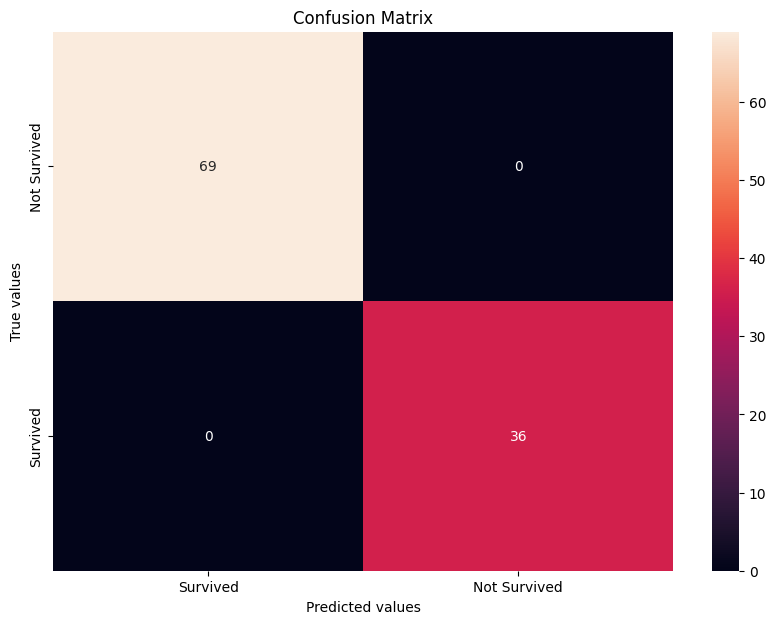

In [93]:
plot_model(matrix)